In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [2]:
train_dir = "/Users/abubakartamboli/Downloads/cats_and_dogs_filtered/train"
validation_dir = "/Users/abubakartamboli/Downloads/cats_and_dogs_filtered/validation"

In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary"
)

# Load validation dataset
validation_ds = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary"
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


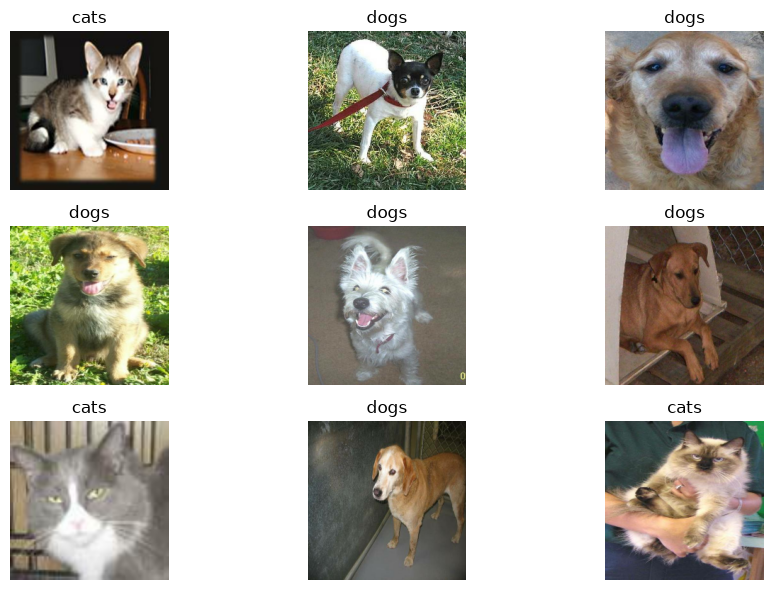

In [5]:
plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy().item())
        plt.title(class_names[label])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y)
).prefetch(AUTOTUNE)

validation_ds = validation_ds.map(
    lambda x, y: (preprocess_input(x), y)
).prefetch(AUTOTUNE)

In [7]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [8]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
history = model.fit(
    train_ds,
    epochs=5,
    validation_data=validation_ds
)

Epoch 1/5


/opt/anaconda3/envs/tf-env/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 229ms/step - accuracy: 0.9670 - loss: 0.0990 - val_accuracy: 0.9870 - val_loss: 0.0378
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 217ms/step - accuracy: 0.9895 - loss: 0.0318 - val_accuracy: 0.9880 - val_loss: 0.0267
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 224ms/step - accuracy: 0.9950 - loss: 0.0126 - val_accuracy: 0.9880 - val_loss: 0.0300
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 220ms/step - accuracy: 0.9965 - loss: 0.0094 - val_accuracy: 0.9890 - val_loss: 0.0285
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 227ms/step - accuracy: 0.9985 - loss: 0.0048 - val_accuracy: 0.9900 - val_loss: 0.0327


In [10]:
loss, accuracy = model.evaluate(validation_ds)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 149ms/step - accuracy: 0.9900 - loss: 0.0327    
Validation Loss: 0.032651182264089584
Validation Accuracy: 99.00000095367432 %


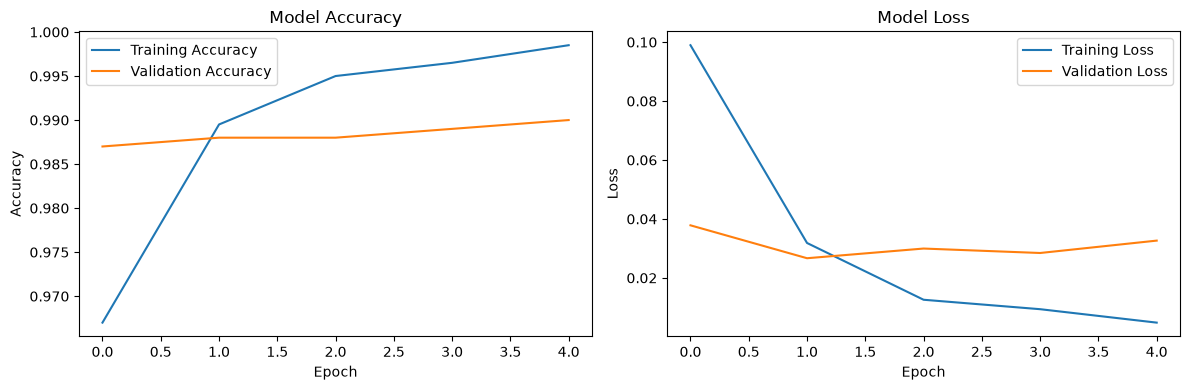

In [11]:
plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step


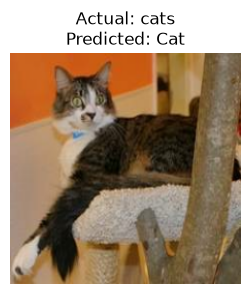

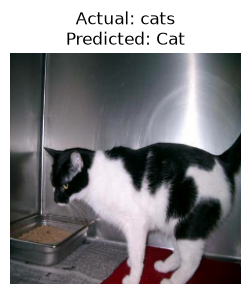

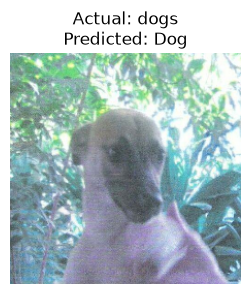

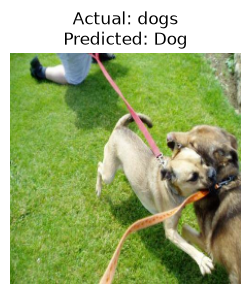

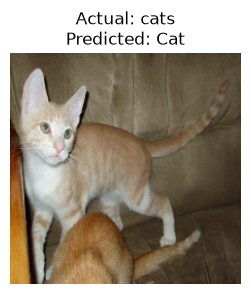

In [13]:
for images, labels in validation_ds.take(1):

    predictions = model.predict(images)

    for i in range(5):

        # Predicted probability
        probability = predictions[i][0]

        if probability >= 0.5:
            predicted_class = "Dog"
        else:
            predicted_class = "Cat"

        # FIX: Extract scalar label
        actual_label = int(labels[i].numpy().item())
        actual_class = class_names[actual_label]

        # Reverse MobileNetV2 preprocessing for display
        display_image = (images[i].numpy() + 1.0) * 127.5
        display_image = np.clip(display_image, 0, 255).astype("uint8")

        plt.figure(figsize=(3, 3))
        plt.imshow(display_image)

        plt.title(
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}"
        )

        plt.axis("off")
        plt.show()